# Наивный прогноз, деление на трейн и тест, скользящие окна: задел к чекпоинту 3

Разделы про k по периодам и тест ADF перенесены в ноутбук notebooks/01_eda_prices_target.ipynb, в раздел 3. В этом ноутбуке мы проверяем модели.

| Задание | Раздел |
|---|---|
| Посмотреть, что показывает наивный прогноз каждый месяц | 1 |
| Разделить ряд на трейн и тест, попробовать скользящие окна и выполнять предобработку только после деления | 2 |
| Дополнительно: проверить, можно ли удлинить ряд цены газа до 2015 года | 3 |

**Трейн** охватывает период с апреля 2015 по сентябрь 2023 года (102 месяца), **тест** охватывает период с октября 2023 по сентябрь 2026 года (36 месяцев). Все решения, то есть выбор k и выбор модели, мы принимаем только на трейне.

In [ ]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_parquet("../data/processed/prices_monthly.parquet")
df = df.loc["2015-04":]
train = df.loc[:"2023-09"]
print("Весь период:", df.index.min().date(), "–", df.index.max().date(), len(df), "мес.")
print("Трейн:", train.index.min().date(), "–", train.index.max().date(), len(train), "мес.")

Весь период: 2015-04-01 – 2026-09-01 138 мес.
Трейн: 2015-04-01 – 2023-09-01 102 мес.


## 1. Наивный прогноз каждый месяц

Наивный прогноз предполагает, что цена через h месяцев будет равна цене сейчас. Это базовый прогноз, который модель должна обыграть. Ошибку на тестовой выборке мы считаем только для наивного прогноза, потому что у него нет параметров и подсмотреть в тесте ему нечего.

 горизонт                        период  прогнозов  RMSE, $/т  MAE, $/т  MAPE, %
        1    трейн: апр 2015 – сен 2023        102       53.0      29.9      8.1
        1 спокойно: апр 2015 – июн 2021         75       23.4      16.3      6.9
        1   кризис: июл 2021 – дек 2022         18      112.7      83.7     12.1
        1     тест: окт 2023 – сен 2026         35       80.2      46.6      9.9
        3    трейн: апр 2015 – сен 2023        102       99.7      56.6     15.0
        3 спокойно: апр 2015 – июн 2021         75       39.5      29.8     11.9
        3   кризис: июл 2021 – дек 2022         18      218.4     171.1     28.1
        3     тест: окт 2023 – сен 2026         33      166.1     103.5     21.8


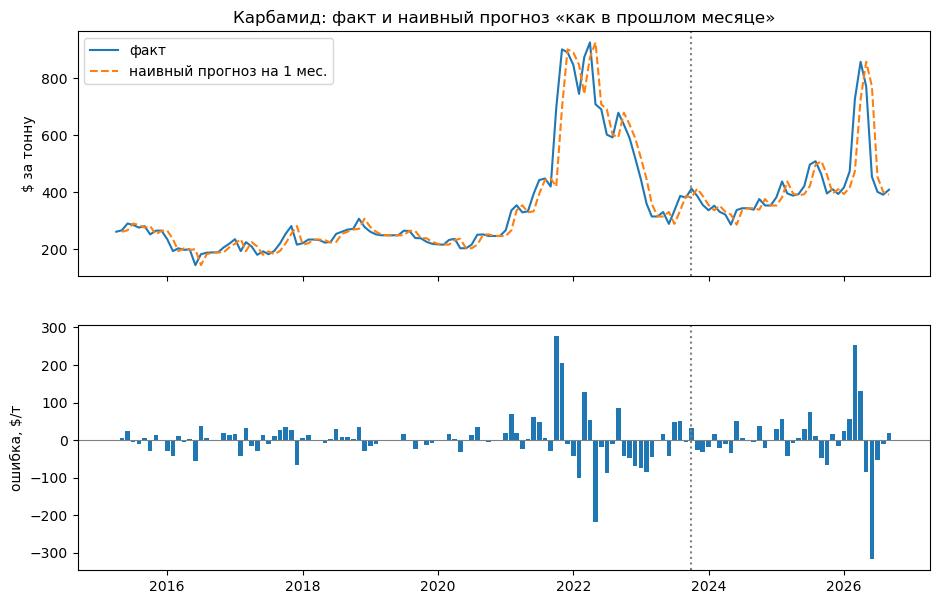

In [ ]:
price = df["urea_price"]
gas = df["gas_europe"]

periods = {
    "трейн: апр 2015 – сен 2023": ("2015-04", "2023-09"),
    "спокойно: апр 2015 – июн 2021": ("2015-04", "2021-06"),
    "кризис: июл 2021 – дек 2022": ("2021-07", "2022-12"),
    "тест: окт 2023 – сен 2026": ("2023-10", "2026-09"),
}

rows = []
for h in [1, 3]:
    error = (price.shift(-h) - price).dropna()
    pct = (error.abs() / price.shift(-h)).dropna() * 100
    for name, (start, end) in periods.items():
        e = error.loc[start:end]
        rows.append({
            "горизонт": h,
            "период": name,
            "прогнозов": len(e),
            "RMSE, $/т": round(np.sqrt((e ** 2).mean()), 1),
            "MAE, $/т": round(e.abs().mean(), 1),
            "MAPE, %": round(pct.loc[start:end].mean(), 1),
        })
print(pd.DataFrame(rows).to_string(index=False))

naive = price.shift(1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(price.index, price, label="факт")
ax1.plot(naive.index, naive, linestyle="--", label="наивный прогноз на 1 мес.")
ax1.set_ylabel("$ за тонну")
ax1.legend()
error_1 = price - naive
ax2.bar(error_1.index, error_1, width=25)
ax2.axhline(0, color="gray", linewidth=0.8)
ax2.set_ylabel("ошибка, $/т")
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp("2023-10-01"), color="gray", linestyle=":")
ax1.set_title("Карбамид: факт и наивный прогноз «как в прошлом месяце»")
plt.show()

**Главный результат: в спокойные месяцы наивный прогноз ошибается в среднем на 7% на горизонте в один месяц и на 12% на горизонте в три месяца, и обыграть его трудно.**

Почти вся ошибка приходится на шоки: осень 2021 года, весну 2022 года и период с марта по июнь 2026 года. Наивный прогноз всегда опаздывает на месяц, потому что он просто повторяет прошлую цену. Значит, модель может выиграть у наивного прогноза только на поворотах цены, а для этого нужны признаки, которые сообщают о шоке заранее.

Обыгрывают ли наивный прогноз простые модели? Мы сравниваем их на валидации внутри трейна, сдвигая начало прогноза на каждом шаге. В таблице указано отношение ошибки модели (MSE) к ошибке наивного прогноза. **Если отношение меньше 1, модель лучше наивного прогноза.**

In [ ]:
def rolling_forecast(h, k, origins, use_gas_change=False):
    if use_gas_change:
        base = price
        feature = gas.diff()
    else:
        base = k * gas
        feature = price - k * gas
    target = price.shift(-h) - base
    table = pd.DataFrame({"x": feature, "y": target})
    results = []
    for origin in origins:
        known = table.loc[:origin - pd.DateOffset(months=h)].dropna()
        slope, intercept = np.polyfit(known["x"], known["y"], 1)
        prediction = base.loc[origin] + intercept + slope * table.loc[origin, "x"]
        results.append((price.shift(-h).loc[origin], price.loc[origin], prediction))
    r = np.array(results)
    mse_naive = ((r[:, 0] - r[:, 1]) ** 2).mean()
    mse_model = ((r[:, 0] - r[:, 2]) ** 2).mean()
    return round(mse_model / mse_naive, 2)


windows = {
    "спокойно: янв 2018 – июн 2021": ("2018-01", "2021-06"),
    "валидация: окт 2020 – сен 2023": ("2020-10", "2023-09"),
}
rows = []
for wname, (start, end) in windows.items():
    for h in [1, 3]:
        origins = df.loc[start:end].index
        origins = origins[origins <= pd.Timestamp(end) - pd.DateOffset(months=h)]
        row = {"окно": wname, "горизонт": h}
        for k in [12, 13, 26]:
            row[f"возврат к норме, k={k}"] = rolling_forecast(h, k, origins)
        row["изменение газа"] = rolling_forecast(h, 0, origins, use_gas_change=True)
        rows.append(row)
print("Отношение MSE модели к MSE наивного прогноза (меньше 1 — модель лучше):")
print(pd.DataFrame(rows).to_string(index=False))

Отношение MSE модели к MSE наивного прогноза (меньше 1 — модель лучше):
                          окно  горизонт  возврат к норме, k=12  возврат к норме, k=13  возврат к норме, k=26  изменение газа
 спокойно: янв 2018 – июн 2021         1                   1.18                   1.19                   1.27            0.96
 спокойно: янв 2018 – июн 2021         3                   1.36                   1.37                   1.59            1.04
валидация: окт 2020 – сен 2023         1                   1.07                   1.07                   1.26            1.08
валидация: окт 2020 – сен 2023         3                   1.27                   1.25                   1.55            1.66


**Две простые модели.** Обе являются линейной регрессией с одним признаком и заново обучаются каждый месяц только на прошлых данных.
- **«Возврат к норме».** Признак: текущая надбавка. Прогноз цены равен k × текущая цена газа плюс прогноз надбавки. По сути это модель AR(1).
- **«Изменение газа».** Признак: изменение цены газа за месяц. Прогноз цены равен текущей цене плюс прогноз изменения цены.

**Главный результат: ни одна из простых моделей не обыгрывает наивный прогноз устойчиво.**
- Модель «возврат к норме» проигрывает наивному прогнозу при любом k. Причина в том, что норма надбавки сама со временем сдвигается, а модель тянет прогноз к старому среднему значению. Стационарность надбавки ещё не означает, что модель возврата к норме обыграет наивный прогноз на горизонте в 1 и 3 месяца.
- Среди вариантов k лучше всего работают k = 12 и k = 13, а хуже всего k = 26. Поэтому для целевой переменной мы берём k около 12, оценённый на трейне.
- Модель «изменение газа» немного лучше наивного прогноза в спокойные месяцы на горизонте в один месяц, но в кризис эта простая модель ломается.

## 2. Деление на трейн и тест, скользящие окна, предобработка после деления

Общий код проверки моделей вынесен в файл src/models/backtest.py, чтобы все модели команды сравнивались одинаково.
- Функция split_train_test делит данные только по времени: тест начинается с октября 2023 года.
- Функция rolling_backtest строит прогноз со скользящим началом. На каждом месяце модель обучается только на тех строках, ответ для которых уже известен, то есть на строках до месяца origin минус h. Окно обучения бывает **расширяющимся**, когда используется вся история, или **скользящим**, когда используются последние N месяцев.
- Предобработка (масштабирование признаков) выполняется внутри модели и обучается только на известных строках. Таким образом, мы сначала делим данные, а затем выполняем предобработку.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.models.backtest import make_table, split_train_test, rolling_backtest, score

h = 1
table = make_table(df, h)
train_t, test_t = split_train_test(table)
print("Трейн:", train_t.index.min().date(), "–", train_t.index.max().date(), len(train_t), "мес.")
print("Тест: ", test_t.index.min().date(), "–", test_t.index.max().date(), len(test_t), "мес.")


def gas_change_model(known, now):
    slope, intercept = np.polyfit(known["gas_change"], known["y"] - known["price"], 1)
    return now["price"].iloc[0] + intercept + slope * now["gas_change"].iloc[0]


features = ["gas_change", "gas_change_lag1", "price_change"]


def ridge_model(known, now):
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(known[features], known["y"] - known["price"])
    return now["price"].iloc[0] + model.predict(now[features])[0]


valid_origins = train_t.loc["2020-10":].index
valid_origins = valid_origins[valid_origins <= train_t.index.max() - pd.DateOffset(months=h)]

for name, model in [("изменение газа", gas_change_model), ("ridge, 3 признака", ridge_model)]:
    for window in [None, 60, 36]:
        results = rolling_backtest(table, h, model, valid_origins, window=window)
        label = "расширяющееся" if window is None else f"скользящее {window} мес."
        print(f"\n{name} | окно: {label}")
        print(score(results).to_string())

Трейн: 2015-04-01 – 2023-09-01 102 мес.
Тест:  2023-10-01 – 2026-09-01 36 мес.

изменение газа | окно: расширяющееся
             прогнозов  RMSE модели  RMSE наивного  MSE модель / наивный
все               35.0         89.2           85.7                  1.08
без кризиса       17.0         31.8           41.0                  0.60
кризис            18.0        120.5          112.7                  1.14

изменение газа | окно: скользящее 60 мес.
             прогнозов  RMSE модели  RMSE наивного  MSE модель / наивный
все               35.0         89.9           85.7                  1.10
без кризиса       17.0         31.6           41.0                  0.59
кризис            18.0        121.6          112.7                  1.16

изменение газа | окно: скользящее 36 мес.
             прогнозов  RMSE модели  RMSE наивного  MSE модель / наивный
все               35.0         91.2           85.7                  1.13
без кризиса       17.0         31.4           41.0                 

**Главный результат: вне кризиса модели на ценах заметно лучше наивного прогноза, а весь проигрыш приходится на кризис 2021 и 2022 годов.**
- **Вне кризиса** ошибка моделей (MSE) меньше ошибки наивного прогноза на величину от 40 до 45%. Однако таких месяцев в окне валидации всего 17, поэтому этот вывод предварительный.
- **В кризис 2021 и 2022 годов** модели ошибаются сильнее наивного прогноза, и поэтому общий результат оказывается больше 1. Модели нужны признак режима рынка и признаки шоков: трафик через проливы, экспорт Китая, индекс GSCPI.
- **Скользящие окна не помогают.** Расширяющееся окно работает не хуже скользящего, а в кризис даже лучше, потому что короткое окно «забывает» прошлые шоки. Поэтому основным вариантом мы выбираем расширяющееся окно, а скользящие окна в 60 и 36 месяцев используем для проверки устойчивости.
- Тестовую выборку мы не используем, пока не выбрана финальная модель.

## 3. Можно ли удлинить ряд цены газа до 2015 года?

В Pink Sheet цена газа Европы есть с 1960 года, но **до апреля 2015 года это другой показатель**. До этой даты это цена импорта газа на границе, которая в основном определялась долгосрочными контрактами с привязкой к нефти. В период с 2010 года по март 2015 года к ней добавлялась спотовая составляющая по Великобритании. Мы проверяем, похожа ли связь цены газа с ценой карбамида до апреля 2015 года и после.

In [ ]:
full = pd.read_parquet("../data/processed/prices_monthly.parquet")
rows = []
for name, (start, end) in {
    "2000–2009 (контракты)": ("2000-01", "2009-12"),
    "2010 – мар 2015 (контракты + спот)": ("2010-01", "2015-03"),
    "апр 2015 – сен 2023 (TTF, трейн)": ("2015-04", "2023-09"),
}.items():
    part = full.loc[start:end]
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    gas_change = np.log(part["gas_europe"]).diff()
    urea_next = np.log(part["urea_price"]).diff().shift(-1)
    rows.append({
        "период": name,
        "месяцев": len(part),
        "k (наклон)": round(fit.slope, 1),
        "± 95%": round(1.96 * fit.stderr, 1),
        "изменение газа → карбамид через месяц": round(gas_change.corr(urea_next), 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

                            период  месяцев  k (наклон)  ± 95%  изменение газа → карбамид через месяц
             2000–2009 (контракты)      120        35.6    4.0                                   0.04
2010 – мар 2015 (контракты + спот)       63        27.9   11.2                                   0.05
  апр 2015 – сен 2023 (TTF, трейн)      102        12.0    1.5                                   0.38


**Главный результат: ряд цены газа до 2015 года нельзя склеивать с рядом TTF, потому что до 2015 года изменение цены газа не помогает прогнозировать цену карбамида.**

До 2015 года наклон в уровнях больше: k составляет от 28 до 36 против 12 на трейне с TTF. Однако этот наклон скорее отражает общий нефтяной цикл двухтысячных годов. Главное, что корреляция изменения цены газа с изменением цены карбамида через месяц до 2015 года составляет около 0,05, тогда как в период TTF она составляет около 0,38. Склейка двух рядов испортила бы целевую переменную, потому что одного значения k на весь период нет. Поэтому основная модель строится на данных с апреля 2015 года. Длинный ряд можно использовать только для проверки устойчивости с флагом gas_oil_indexed и разными значениями k. Настоящая история цен TTF до 2015 года есть в платных источниках: ICE Endex, Bloomberg, Argus.